# RQ1: Can we identify which LLM generated a response?

**Task.** Given only an LLM's response text (`Answer`), predict which model
produced it (`Source`). This is multi-class text classification.

**Dataset.** TXD-22 (Kaggle: `mdsadiqiqbal/txd-22-a-large-scale-benchmark-dataset`).
One CSV with three columns: `Question` (the user prompt), `Answer` (the LLM
output) and `Source` (the LLM that wrote it).

**Models.**
1. TF-IDF + Logistic Regression: a classical reference baseline.
2. TextCNN (Kim, 2014): parallel 1-D convolutions with max-over-time pooling.
3. BiLSTM: a bidirectional LSTM whose final hidden states feed a classifier.

**Evaluation protocol.** The split is made *by question*, so every question in
the test set is unseen during training. Otherwise a model could score well by
memorising which LLMs answered which topics instead of learning their writing
style. We report accuracy and macro-F1 (each LLM counts equally).


In [1]:
import copy
import json
import random
import re
import subprocess
import sys
import time
from collections import Counter
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import DataLoader, TensorDataset

try:
    import kagglehub
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub

In [2]:
@dataclass
class Config:
    # --- Data ---
    dataset_handle: str = "mdsadiqiqbal/txd-22-a-large-scale-benchmark-dataset"
    csv_path: str | None = None
    text_col: str = "Answer"
    prompt_col: str = "Question"
    label_col: str = "Source"
    # TXD-22 also contains human-written and mixed human/AI labels. Drop those ones.
    non_llm_label_pattern: str | None = r"(?i)human|ai-generated|ai-refined"

    # --- Class balancing ---
    min_samples_per_class: int = 500  # Drop LLMs with fewer answers than this.
    max_samples_per_class: int | None = 3000  # Downsample larger classes; None keeps all.

    # --- Splits (fractions of the whole dataset, split by question) ---
    test_size: float = 0.15
    val_size: float = 0.15

    # --- Text preprocessing ---
    max_vocab_size: int = 50_000
    min_token_freq: int = 2
    max_seq_len: int = 400  # Tokens kept from the start of each answer.

    # --- Shared neural-network hyperparameters ---
    embed_dim: int = 128
    dropout: float = 0.5
    batch_size: int = 64
    epochs: int = 10
    learning_rate: float = 1e-3
    weight_decay: float = 1e-4
    patience: int = 3  # Early stopping: epochs without val macro-F1 improvement.
    grad_clip: float = 1.0

    # --- TextCNN ---
    cnn_num_filters: int = 128
    cnn_kernel_sizes: tuple[int, ...] = (3, 4, 5)

    # --- BiLSTM ---
    lstm_hidden_dim: int = 128
    lstm_num_layers: int = 1

    # --- Misc ---
    seed: int = 42
    results_dir: str = "results"


CONFIG = Config()
RESULTS_DIR = Path(CONFIG.results_dir)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")


def set_seed(seed: int) -> None:
    """Make runs reproducible across Python, NumPy and PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(CONFIG.seed)

Device: cuda


## 1. Load the data

In [3]:
def load_raw_dataset(cfg: Config) -> pd.DataFrame:
    """Read the TXD-22 CSV from a local path or download it from Kaggle."""
    if cfg.csv_path:
        csv_file = Path(cfg.csv_path)
    else:
        download_dir = Path(kagglehub.dataset_download(cfg.dataset_handle))
        csv_file = next(download_dir.rglob("*.csv"))
    print(f"Reading {csv_file}")
    # The file contains a few invalid UTF-8 bytes; replace them instead of crashing. Ys.
    return pd.read_csv(csv_file, encoding="utf-8", encoding_errors="replace")


raw_df = load_raw_dataset(CONFIG)
print(f"Raw shape: {raw_df.shape}")
raw_df.head()

Using Colab cache for faster access to the 'txd-22-a-large-scale-benchmark-dataset' dataset.
Reading /kaggle/input/txd-22-a-large-scale-benchmark-dataset/TXD-22 A Large-Scale Benchmark Dataset.csv
Raw shape: (66000, 3)


,Question,Answer,Source
0,What is the difference between an array and a ...,An array and a linked list are both linear dat...,ChatGPT
1,How does a stack differ from a queue?,A stack and a queue are both abstract data str...,ChatGPT
2,What is a binary search tree? Explain insertio...,A binary search tree (BST) is a specialized fo...,ChatGPT
3,Explain the concept of recursion with an example.,Recursion is a programming technique where a f...,ChatGPT
4,How does merge sort work? What is its time com...,Merge sort is a divide-and-conquer sorting alg...,ChatGPT


## 2. Clean and balance

* Drop rows with missing or empty text.
* Drop exact duplicate (answer, source) pairs.
* Drop answers that appear under more than one source: their label is ambiguous.
* Drop the human-written and mixed human/AI labels, which are not LLMs.
* Keep LLMs with at least `min_samples_per_class` answers and downsample each
  to at most `max_samples_per_class`, so the classes are roughly balanced.

In [4]:
def clean_dataset(df: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    columns = [cfg.prompt_col, cfg.text_col, cfg.label_col]
    df = df[columns].dropna().copy()
    for col in columns:
        df[col] = df[col].astype(str).str.strip()
    df = df[df[cfg.text_col].str.len() > 0]

    before = len(df)
    df = df.drop_duplicates(subset=[cfg.text_col, cfg.label_col])
    df = df.drop_duplicates(subset=[cfg.text_col], keep=False)
    print(f"Removed {before - len(df):,} duplicate or ambiguous answers")
    return df.reset_index(drop=True)


def drop_non_llm_labels(df: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    if cfg.non_llm_label_pattern is None:
        return df
    is_non_llm = df[cfg.label_col].str.contains(cfg.non_llm_label_pattern, regex=True)
    print(f"Dropping non-LLM labels: {sorted(df.loc[is_non_llm, cfg.label_col].unique())}")
    return df[~is_non_llm].reset_index(drop=True)


def balance_classes(df: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    counts = df[cfg.label_col].value_counts()
    kept_labels = counts[counts >= cfg.min_samples_per_class].index
    dropped = sorted(set(counts.index) - set(kept_labels))
    if dropped:
        print(f"Dropping classes with < {cfg.min_samples_per_class} samples: {dropped}")
    df = df[df[cfg.label_col].isin(kept_labels)]

    if cfg.max_samples_per_class is not None:
        shuffled = df.sample(frac=1, random_state=cfg.seed)
        df = shuffled.groupby(cfg.label_col).head(cfg.max_samples_per_class)
    return df.reset_index(drop=True)


clean_df = drop_non_llm_labels(clean_dataset(raw_df, CONFIG), CONFIG)
data_df = balance_classes(clean_df, CONFIG)
print(f"Final dataset: {len(data_df):,} answers, "
      f"{data_df[CONFIG.label_col].nunique()} LLMs, "
      f"{data_df[CONFIG.prompt_col].nunique():,} unique questions")

Removed 48 duplicate or ambiguous answers
Dropping non-LLM labels: ['AI-generated and AI-refined', 'AI-generated and AI-refined and Human-written', 'AI-generated�and Human-written', 'Human written', 'Human-written and AI-refined']
Final dataset: 50,980 answers, 17 LLMs, 3,076 unique questions


## 3. Exploratory statistics

Class counts and answer lengths per LLM. Length alone is often a strong
signal, so keep these numbers in mind when interpreting the classifiers.

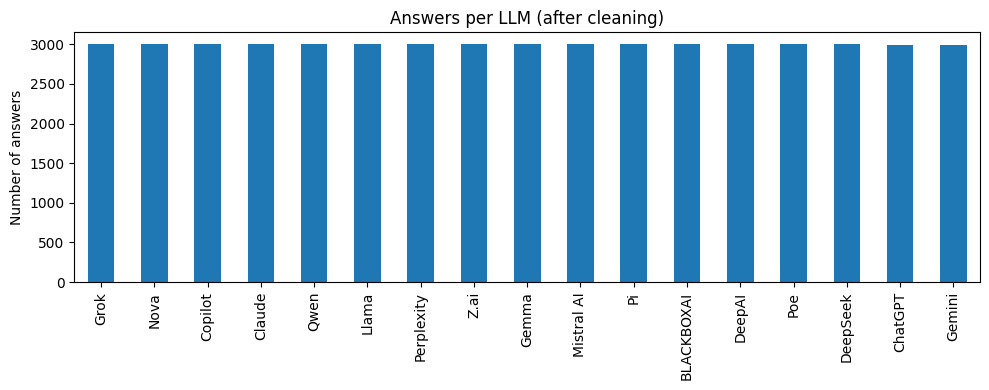

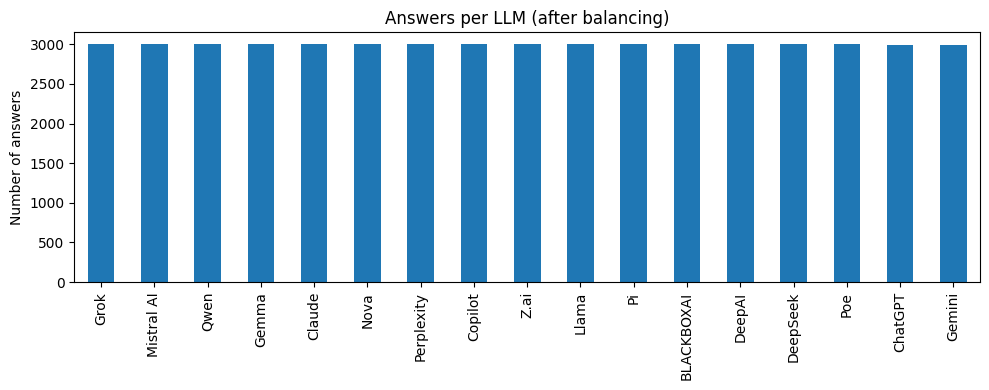

Answer length (words) per LLM:
             mean    50%    std    min     max
Source                                        
Pi           84.5   84.0   16.1   31.0   210.0
Gemma       141.8  140.5   59.6   40.0   414.0
Z.ai        192.9  193.0   28.2   50.0   557.0
Llama       208.0  206.0   37.9    1.0   375.0
Nova        211.8  207.0   40.7   80.0   541.0
Qwen        216.6  221.0   53.2   67.0   532.0
Mistral AI  228.9  206.0   96.6   56.0   815.0
Perplexity  235.3  248.0   46.1   72.0   341.0
ChatGPT     241.9  239.5   58.6   77.0   798.0
Grok        252.6  266.0   48.3   52.0   668.0
DeepSeek    260.0  260.0   44.0   79.0   677.0
Gemini      262.7  293.0  101.3   70.0   577.0
Poe         276.1  218.0   95.5   97.0   760.0
Claude      295.4  291.0   59.5   85.0  1246.0
Copilot     302.2  319.0   55.8   62.0   637.0
DeepAI      313.9  315.0   36.7  171.0   459.0
BLACKBOXAI  343.7  362.0   81.3   29.0   833.0


In [5]:
def plot_class_counts(df: pd.DataFrame, cfg: Config, title: str, filename: str) -> None:
    counts = df[cfg.label_col].value_counts()
    fig, ax = plt.subplots(figsize=(10, 4))
    counts.plot.bar(ax=ax)
    ax.set_xlabel("")
    ax.set_title(title)
    ax.set_ylabel("Number of answers")
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / filename, dpi=150)
    plt.show()


plot_class_counts(clean_df, CONFIG, "Answers per LLM (after cleaning)", "class_counts_raw.png")
plot_class_counts(data_df, CONFIG, "Answers per LLM (after balancing)", "class_counts_balanced.png")

word_counts = data_df[CONFIG.text_col].str.split().str.len()
length_stats = word_counts.groupby(data_df[CONFIG.label_col]).describe()[
    ["mean", "50%", "std", "min", "max"]
].round(1).sort_values("mean")
length_stats.to_csv(RESULTS_DIR / "answer_length_by_llm.csv")
print("Answer length (words) per LLM:")
print(length_stats.to_string())

## 4. Train / validation / test split (grouped by question)

`StratifiedGroupKFold` keeps all answers to the same question in the same
split while keeping the class proportions similar across splits.

In [6]:
def grouped_split(
    df: pd.DataFrame, holdout_frac: float, cfg: Config
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Split off roughly `holdout_frac` of rows with no question shared between parts."""
    n_splits = max(2, round(1 / holdout_frac))
    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=cfg.seed)
    keep_idx, holdout_idx = next(
        splitter.split(df, df[cfg.label_col], groups=df[cfg.prompt_col])
    )
    return df.iloc[keep_idx].reset_index(drop=True), df.iloc[holdout_idx].reset_index(drop=True)


train_val_df, test_df = grouped_split(data_df, CONFIG.test_size, CONFIG)
val_frac_of_remaining = CONFIG.val_size / (1 - CONFIG.test_size)
train_df, val_df = grouped_split(train_val_df, val_frac_of_remaining, CONFIG)

# Sanity check: no question may appear in more than one split.
train_q, val_q, test_q = (set(d[CONFIG.prompt_col]) for d in (train_df, val_df, test_df))
assert not (train_q & val_q) and not (train_q & test_q) and not (val_q & test_q)

for name, split in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:>5}: {len(split):6,} answers ({len(split) / len(data_df):.1%}), "
          f"{split[CONFIG.prompt_col].nunique():,} questions")

# Map class names to integer ids (sorted so the order is stable across runs).
CLASS_NAMES = sorted(data_df[CONFIG.label_col].unique())
LABEL_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
y_train = train_df[CONFIG.label_col].map(LABEL_TO_ID).to_numpy()
y_val = val_df[CONFIG.label_col].map(LABEL_TO_ID).to_numpy()
y_test = test_df[CONFIG.label_col].map(LABEL_TO_ID).to_numpy()

train: 36,369 answers (71.3%), 2,197 questions
  val:  7,296 answers (14.3%), 439 questions
 test:  7,315 answers (14.3%), 440 questions


## 5. Evaluation helpers

In [7]:
ALL_RESULTS: dict[str, dict] = {}


def slugify(name: str) -> str:
    """Turn a model name into a safe filename stem, e.g. 'TF-IDF + LogReg' -> 'tf_idf_logreg'."""
    return re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")


def evaluate_predictions(model_name: str, y_true: np.ndarray, y_pred: np.ndarray, **extra) -> None:
    """Print a report, save a confusion matrix and record the headline metrics."""
    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    print(f"\n=== {model_name} | test accuracy {accuracy:.4f} | macro-F1 {macro_f1:.4f} ===")

    report = classification_report(
        y_true, y_pred, labels=range(len(CLASS_NAMES)), target_names=CLASS_NAMES,
        digits=3, zero_division=0,
    )
    print(report)
    slug = slugify(model_name)
    (RESULTS_DIR / f"report_{slug}.txt").write_text(report)

    fig, ax = plt.subplots(figsize=(12, 10))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, labels=range(len(CLASS_NAMES)), display_labels=CLASS_NAMES,
        normalize="true", values_format=".2f", xticks_rotation=90,
        cmap="Blues", ax=ax, text_kw={"fontsize": 6},
    )
    ax.set_title(f"{model_name}: normalised confusion matrix (test set)")
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f"confusion_{slug}.png", dpi=150)
    plt.show()

    ALL_RESULTS[model_name] = {"accuracy": accuracy, "macro_f1": macro_f1, **extra}

## 6. Baselines

* **Majority class**: the chance-level floor.
* **TF-IDF + Logistic Regression**: word uni/bi-grams. A strong, cheap
  reference point for the neural models.


=== Majority class | test accuracy 0.0584 | macro-F1 0.0065 ===
              precision    recall  f1-score   support

  BLACKBOXAI      0.000     0.000     0.000       431
     ChatGPT      0.000     0.000     0.000       427
      Claude      0.000     0.000     0.000       430
     Copilot      0.000     0.000     0.000       430
      DeepAI      0.058     1.000     0.110       427
    DeepSeek      0.000     0.000     0.000       429
      Gemini      0.000     0.000     0.000       431
       Gemma      0.000     0.000     0.000       431
        Grok      0.000     0.000     0.000       431
       Llama      0.000     0.000     0.000       431
  Mistral AI      0.000     0.000     0.000       433
        Nova      0.000     0.000     0.000       431
  Perplexity      0.000     0.000     0.000       431
          Pi      0.000     0.000     0.000       433
         Poe      0.000     0.000     0.000       431
        Qwen      0.000     0.000     0.000       428
        Z.ai    

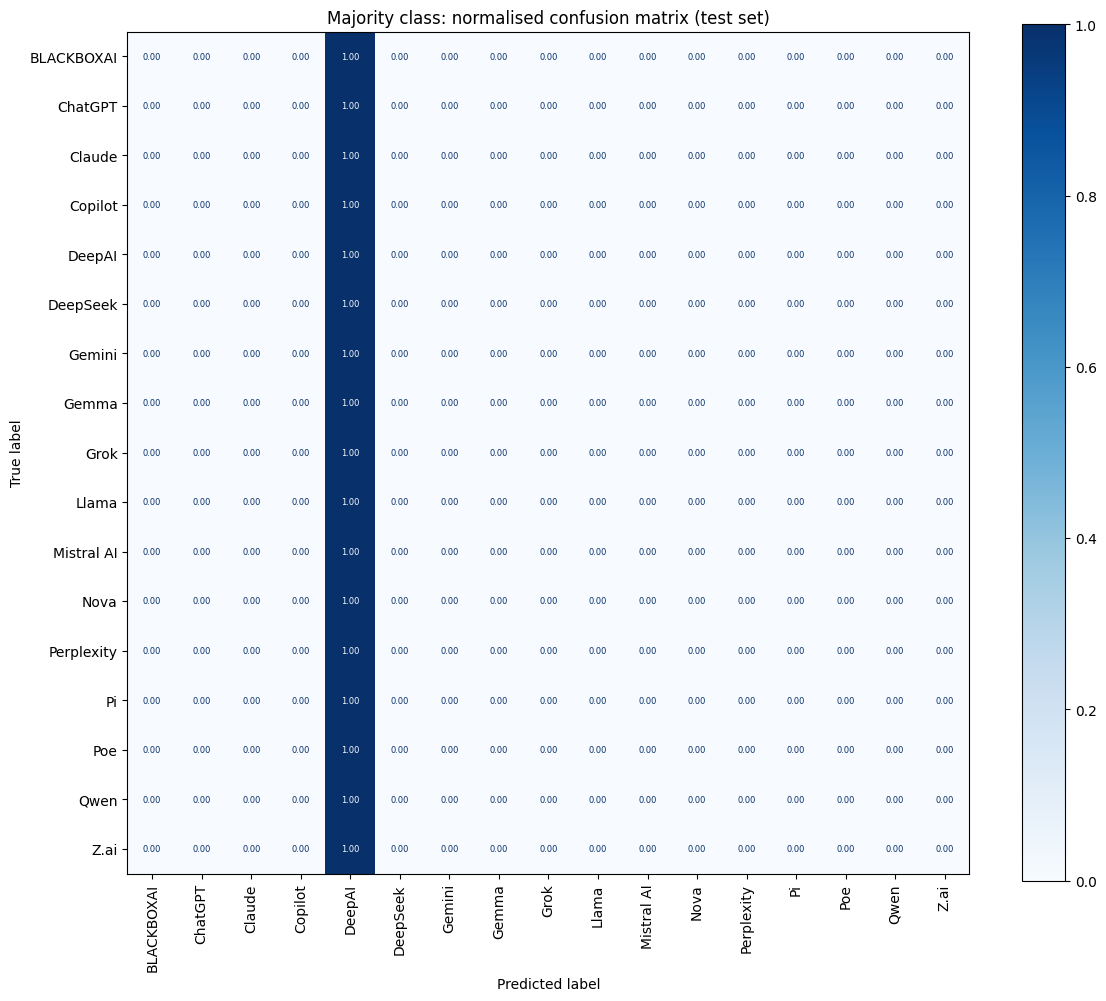


=== TF-IDF + LogReg | test accuracy 0.7290 | macro-F1 0.7230 ===
              precision    recall  f1-score   support

  BLACKBOXAI      0.631     0.770     0.694       431
     ChatGPT      0.530     0.351     0.423       427
      Claude      0.860     0.902     0.881       430
     Copilot      0.677     0.707     0.692       430
      DeepAI      0.769     0.904     0.831       427
    DeepSeek      0.731     0.730     0.730       429
      Gemini      0.637     0.826     0.719       431
       Gemma      0.715     0.784     0.748       431
        Grok      0.800     0.912     0.852       431
       Llama      0.855     0.900     0.877       431
  Mistral AI      0.820     0.654     0.728       433
        Nova      0.690     0.599     0.641       431
  Perplexity      0.639     0.564     0.599       431
          Pi      0.736     0.836     0.783       433
         Poe      0.640     0.520     0.574       431
        Qwen      0.796     0.673     0.729       428
        Z.ai   

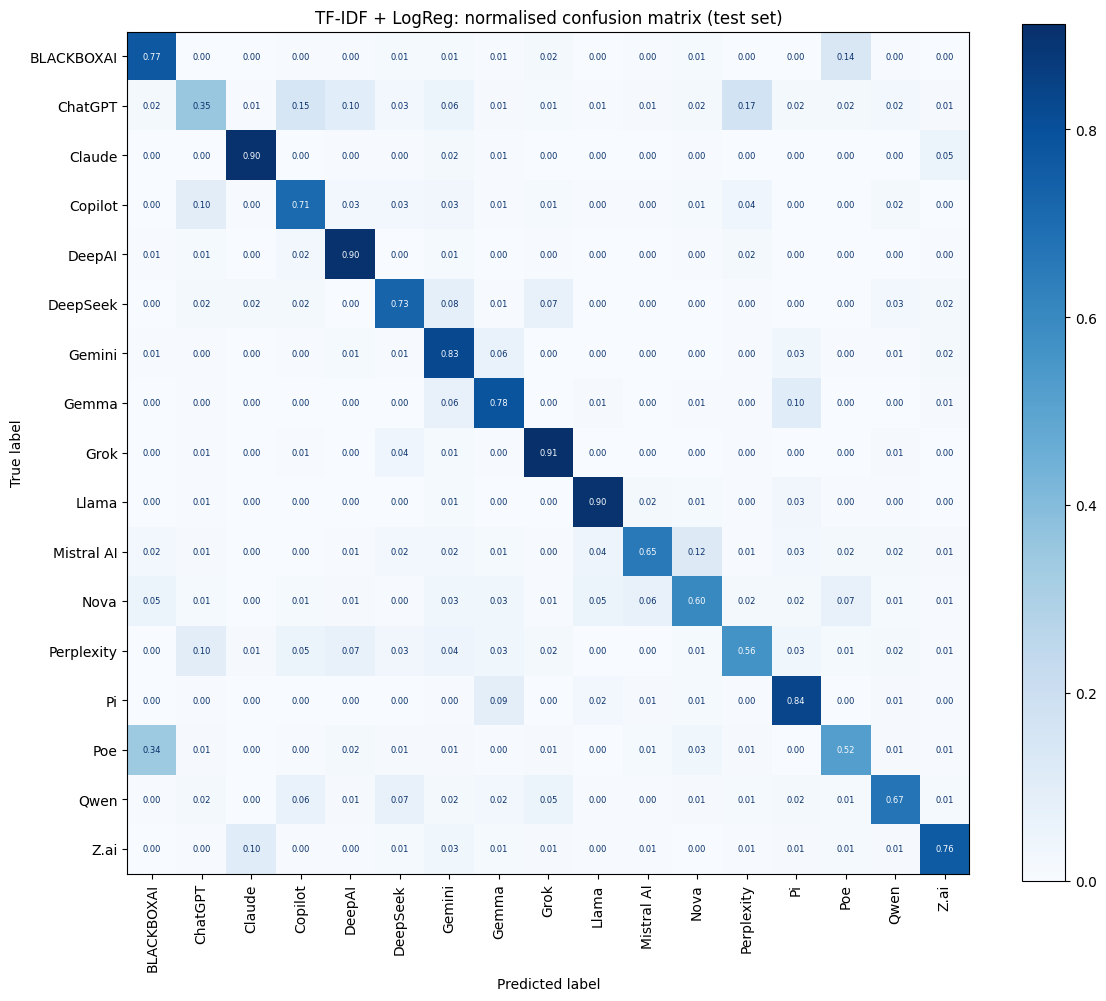

In [8]:
train_text = train_df[CONFIG.text_col].tolist()
test_text = test_df[CONFIG.text_col].tolist()

# The majority baseline ignores its input, so placeholder features are good.
majority = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(y_train), 1)), y_train)
evaluate_predictions("Majority class", y_test, majority.predict(np.zeros((len(y_test), 1))))

start = time.time()
vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=100_000, min_df=2, sublinear_tf=True)
X_train_tfidf = vectorizer.fit_transform(train_text)
X_test_tfidf = vectorizer.transform(test_text)
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_tfidf, y_train)
evaluate_predictions(
    "TF-IDF + LogReg", y_test, log_reg.predict(X_test_tfidf),
    train_seconds=round(time.time() - start, 1),
)

## 7. Tokenisation and vocabulary for the neural models

The tokeniser keeps punctuation and line breaks as separate tokens because
formatting (Markdown bullets, `**bold**`, headings, blank lines) is a likely
stylistic fingerprint. Words are lower-cased to reduce sparsity. The
vocabulary is built from the **training split only**.

In [9]:
TOKEN_PATTERN = re.compile(r"\n|\w+|[^\w\s]")
NEWLINE_TOKEN = "<nl>"


def tokenize(text: str) -> list[str]:
    text = text.replace("\r\n", "\n").lower()
    return [NEWLINE_TOKEN if tok == "\n" else tok for tok in TOKEN_PATTERN.findall(text)]


class Vocabulary:
    PAD_TOKEN, UNK_TOKEN = "<pad>", "<unk>"
    PAD_ID, UNK_ID = 0, 1

    def __init__(self, tokenized_texts: list[list[str]], max_size: int, min_freq: int):
        counter = Counter(tok for tokens in tokenized_texts for tok in tokens)
        frequent = [tok for tok, freq in counter.most_common(max_size - 2) if freq >= min_freq]
        self.id_to_token = [self.PAD_TOKEN, self.UNK_TOKEN] + frequent
        self.token_to_id = {tok: i for i, tok in enumerate(self.id_to_token)}

    def __len__(self) -> int:
        return len(self.id_to_token)

    def encode(self, tokens: list[str]) -> list[int]:
        return [self.token_to_id.get(tok, self.UNK_ID) for tok in tokens]


def build_tensor_dataset(
    texts: list[str], labels: np.ndarray, vocab: Vocabulary, max_len: int
) -> TensorDataset:
    """Encode texts as a padded (N, max_len) id matrix plus true lengths and labels."""
    token_ids = torch.full((len(texts), max_len), Vocabulary.PAD_ID, dtype=torch.long)
    lengths = torch.empty(len(texts), dtype=torch.long)
    for row, text in enumerate(texts):
        ids = vocab.encode(tokenize(text)[:max_len]) or [Vocabulary.UNK_ID]
        token_ids[row, : len(ids)] = torch.tensor(ids)
        lengths[row] = len(ids)
    return TensorDataset(token_ids, lengths, torch.as_tensor(labels, dtype=torch.long))


train_tokens = [tokenize(text) for text in train_text]
vocab = Vocabulary(train_tokens, CONFIG.max_vocab_size, CONFIG.min_token_freq)
print(f"Vocabulary size: {len(vocab):,}")

token_counts = pd.Series([len(t) for t in train_tokens])
truncated_share = (token_counts > CONFIG.max_seq_len).mean()
print(f"Tokens per answer: median {token_counts.median():.0f}, "
      f"95th pct {token_counts.quantile(0.95):.0f}; "
      f"{truncated_share:.1%} of answers are truncated at {CONFIG.max_seq_len}")

train_ds = build_tensor_dataset(train_text, y_train, vocab, CONFIG.max_seq_len)
val_ds = build_tensor_dataset(val_df[CONFIG.text_col].tolist(), y_val, vocab, CONFIG.max_seq_len)
test_ds = build_tensor_dataset(test_text, y_test, vocab, CONFIG.max_seq_len)

loader_kwargs = {"batch_size": CONFIG.batch_size, "pin_memory": DEVICE.type == "cuda"}
train_loader = DataLoader(
    train_ds, shuffle=True, generator=torch.Generator().manual_seed(CONFIG.seed), **loader_kwargs
)
val_loader = DataLoader(val_ds, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_ds, shuffle=False, **loader_kwargs)

Vocabulary size: 34,517
Tokens per answer: median 283, 95th pct 451; 14.3% of answers are truncated at 400


## 8. Models

Both models take `(token_ids, lengths)` and return class logits, so they share
one training loop.

**TextCNN.** Embedding → parallel `Conv1d` layers with kernel sizes 3/4/5
(n-gram detectors) → ReLU → max-over-time pooling → dropout → linear layer.

**BiLSTM.** Embedding → dropout → bidirectional LSTM over the *packed*
sequence (padding is skipped) → concatenated final forward and backward
hidden states → dropout → linear layer.

In [10]:
class TextCNN(nn.Module):
    def __init__(
        self, vocab_size: int, embed_dim: int, num_classes: int,
        num_filters: int, kernel_sizes: tuple[int, ...], dropout: float,
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=Vocabulary.PAD_ID)
        self.convs = nn.ModuleList(
            nn.Conv1d(embed_dim, num_filters, kernel_size=k) for k in kernel_sizes
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(num_filters * len(kernel_sizes), num_classes)

    def forward(self, token_ids: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        # Conv1d expects (batch, channels, seq_len).
        embedded = self.embedding(token_ids).transpose(1, 2)
        pooled = [F.relu(conv(embedded)).max(dim=2).values for conv in self.convs]
        return self.classifier(self.dropout(torch.cat(pooled, dim=1)))


class BiLSTMClassifier(nn.Module):
    def __init__(
        self, vocab_size: int, embed_dim: int, num_classes: int,
        hidden_dim: int, num_layers: int, dropout: float,
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=Vocabulary.PAD_ID)
        self.lstm = nn.LSTM(
            embed_dim, hidden_dim, num_layers=num_layers, batch_first=True,
            bidirectional=True, dropout=dropout if num_layers > 1 else 0.0,
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(2 * hidden_dim, num_classes)

    def forward(self, token_ids: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        embedded = self.dropout(self.embedding(token_ids))
        packed = pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, _) = self.lstm(packed)
        # hidden: (num_layers * 2, batch, hidden_dim); take the top layer's two directions.
        final_state = torch.cat([hidden[-2], hidden[-1]], dim=1)
        return self.classifier(self.dropout(final_state))


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## 9. Training loop

* Loss: cross-entropy. Optimiser: AdamW.
* Gradient-norm clipping (needed for the LSTM, harmless for the CNN).
* Early stopping on **validation macro-F1**, restoring the best epoch's weights.

In [11]:
def run_epoch(
    model: nn.Module, loader: DataLoader, criterion: nn.Module,
    optimizer: torch.optim.Optimizer | None = None, grad_clip: float | None = None,
) -> tuple[float, np.ndarray, np.ndarray]:
    """One pass over `loader`. Trains if an optimizer is given, else evaluates.

    Returns (mean loss, predictions, true labels).
    """
    is_training = optimizer is not None
    model.train(is_training)
    total_loss, all_preds, all_labels = 0.0, [], []

    with torch.set_grad_enabled(is_training):
        for token_ids, lengths, labels in loader:
            token_ids, labels = token_ids.to(DEVICE), labels.to(DEVICE)
            logits = model(token_ids, lengths)
            loss = criterion(logits, labels)

            if is_training:
                optimizer.zero_grad()
                loss.backward()
                if grad_clip:
                    nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
                optimizer.step()

            total_loss += loss.item() * len(labels)
            all_preds.append(logits.argmax(dim=1).cpu())
            all_labels.append(labels.cpu())

    preds = torch.cat(all_preds).numpy()
    true = torch.cat(all_labels).numpy()
    return total_loss / len(true), preds, true


def train_model(model: nn.Module, cfg: Config) -> tuple[nn.Module, pd.DataFrame, float]:
    """Train with early stopping and return (best model, per-epoch history, seconds)."""
    model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=cfg.learning_rate, weight_decay=cfg.weight_decay
    )

    history = []
    best_f1, best_state, epochs_without_improvement = -1.0, None, 0
    start = time.time()

    for epoch in range(1, cfg.epochs + 1):
        epoch_start = time.time()
        train_loss, train_pred, train_true = run_epoch(
            model, train_loader, criterion, optimizer, cfg.grad_clip
        )
        val_loss, val_pred, val_true = run_epoch(model, val_loader, criterion)

        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_acc": accuracy_score(train_true, train_pred),
            "val_acc": accuracy_score(val_true, val_pred),
            "val_macro_f1": f1_score(val_true, val_pred, average="macro"),
        }
        history.append(row)
        print(f"epoch {epoch:2d} | train loss {train_loss:.4f} acc {row['train_acc']:.4f} | "
              f"val loss {val_loss:.4f} acc {row['val_acc']:.4f} "
              f"F1 {row['val_macro_f1']:.4f} | {time.time() - epoch_start:.0f}s")

        if row["val_macro_f1"] > best_f1:
            best_f1 = row["val_macro_f1"]
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= cfg.patience:
                print(f"Early stopping: no improvement for {cfg.patience} epochs.")
                break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), time.time() - start


def plot_history(history: pd.DataFrame, model_name: str) -> None:
    fig, (loss_ax, acc_ax) = plt.subplots(1, 2, figsize=(11, 4))
    loss_ax.plot(history["epoch"], history["train_loss"], marker="o", label="train")
    loss_ax.plot(history["epoch"], history["val_loss"], marker="o", label="validation")
    loss_ax.set(title=f"{model_name}: loss", xlabel="epoch", ylabel="cross-entropy")
    acc_ax.plot(history["epoch"], history["train_acc"], marker="o", label="train accuracy")
    acc_ax.plot(history["epoch"], history["val_acc"], marker="o", label="val accuracy")
    acc_ax.plot(history["epoch"], history["val_macro_f1"], marker="o", label="val macro-F1")
    acc_ax.set(title=f"{model_name}: accuracy / F1", xlabel="epoch")
    for ax in (loss_ax, acc_ax):
        ax.legend()
        ax.grid(alpha=0.3)
    fig.tight_layout()
    slug = slugify(model_name)
    fig.savefig(RESULTS_DIR / f"history_{slug}.png", dpi=150)
    history.to_csv(RESULTS_DIR / f"history_{slug}.csv", index=False)
    plt.show()


def train_and_evaluate(model_name: str, model: nn.Module) -> nn.Module:
    """Train one neural model, then evaluate it on the held-out test set."""
    set_seed(CONFIG.seed)
    num_params = count_parameters(model)
    print(f"\n##### {model_name}: {num_params:,} trainable parameters #####")
    model, history, seconds = train_model(model, CONFIG)
    plot_history(history, model_name)

    _, test_pred, test_true = run_epoch(model, test_loader, nn.CrossEntropyLoss())
    evaluate_predictions(
        model_name, test_true, test_pred,
        parameters=num_params, train_seconds=round(seconds, 1),
        best_epoch=int(history["val_macro_f1"].idxmax()) + 1,
    )
    return model

## 10. Train and evaluate the CNN


##### TextCNN: 4,621,713 trainable parameters #####
epoch  1 | train loss 2.3136 acc 0.2675 | val loss 1.5223 acc 0.5219 F1 0.4964 | 12s
epoch  2 | train loss 1.6811 acc 0.4376 | val loss 1.2972 acc 0.5859 F1 0.5684 | 10s
epoch  3 | train loss 1.4485 acc 0.5100 | val loss 1.2328 acc 0.5943 F1 0.5829 | 10s
epoch  4 | train loss 1.2679 acc 0.5711 | val loss 1.1493 acc 0.6103 F1 0.6027 | 10s
epoch  5 | train loss 1.1308 acc 0.6136 | val loss 1.0941 acc 0.6469 F1 0.6413 | 10s
epoch  6 | train loss 1.0114 acc 0.6520 | val loss 1.1043 acc 0.6394 F1 0.6324 | 10s
epoch  7 | train loss 0.9141 acc 0.6834 | val loss 1.1166 acc 0.6349 F1 0.6309 | 10s
epoch  8 | train loss 0.8352 acc 0.7101 | val loss 1.1263 acc 0.6417 F1 0.6390 | 10s
Early stopping: no improvement for 3 epochs.


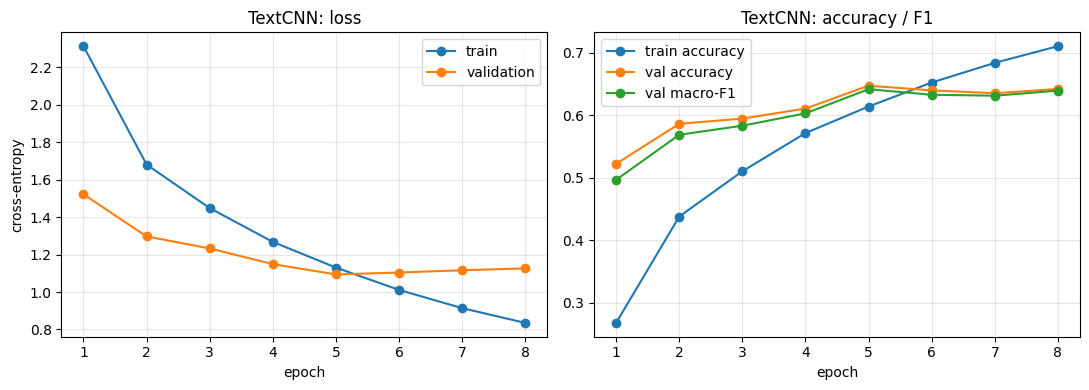


=== TextCNN | test accuracy 0.6376 | macro-F1 0.6321 ===
              precision    recall  f1-score   support

  BLACKBOXAI      0.702     0.657     0.679       431
     ChatGPT      0.380     0.281     0.323       427
      Claude      0.762     0.791     0.776       430
     Copilot      0.517     0.535     0.526       430
      DeepAI      0.627     0.770     0.691       427
    DeepSeek      0.610     0.741     0.669       429
      Gemini      0.602     0.780     0.679       431
       Gemma      0.777     0.703     0.738       431
        Grok      0.850     0.817     0.833       431
       Llama      0.809     0.756     0.782       431
  Mistral AI      0.696     0.594     0.641       433
        Nova      0.392     0.606     0.476       431
  Perplexity      0.525     0.420     0.466       431
          Pi      0.750     0.831     0.789       433
         Poe      0.668     0.290     0.405       431
        Qwen      0.641     0.589     0.614       428
        Z.ai      0.641

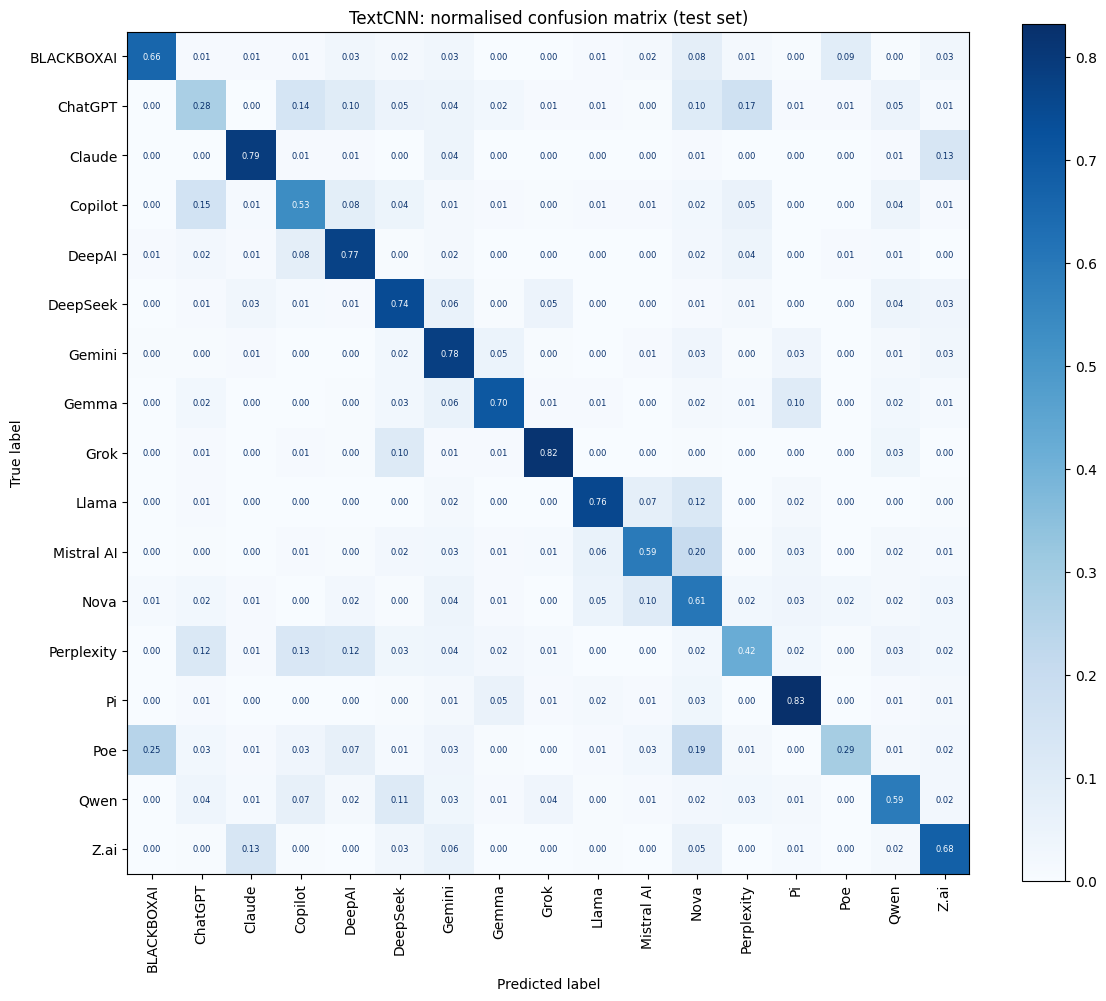

In [12]:
set_seed(CONFIG.seed)
cnn_model = train_and_evaluate(
    "TextCNN",
    TextCNN(
        vocab_size=len(vocab), embed_dim=CONFIG.embed_dim, num_classes=len(CLASS_NAMES),
        num_filters=CONFIG.cnn_num_filters, kernel_sizes=CONFIG.cnn_kernel_sizes,
        dropout=CONFIG.dropout,
    ),
)

## 11. Train and evaluate the RNN (BiLSTM)


##### BiLSTM: 4,686,737 trainable parameters #####
epoch  1 | train loss 2.6437 acc 0.1337 | val loss 2.4135 acc 0.1849 F1 0.1374 | 22s
epoch  2 | train loss 2.1998 acc 0.2615 | val loss 1.9318 acc 0.3348 F1 0.2985 | 22s
epoch  3 | train loss 1.7695 acc 0.3998 | val loss 1.5066 acc 0.4771 F1 0.4604 | 23s
epoch  4 | train loss 1.4935 acc 0.4913 | val loss 1.3537 acc 0.5326 F1 0.5211 | 22s
epoch  5 | train loss 1.3258 acc 0.5538 | val loss 1.1876 acc 0.5931 F1 0.5928 | 22s
epoch  6 | train loss 1.1918 acc 0.5993 | val loss 1.1389 acc 0.6198 F1 0.6137 | 22s
epoch  7 | train loss 1.1078 acc 0.6275 | val loss 1.1530 acc 0.6076 F1 0.6070 | 22s
epoch  8 | train loss 1.0361 acc 0.6534 | val loss 1.0621 acc 0.6349 F1 0.6335 | 23s
epoch  9 | train loss 0.9800 acc 0.6706 | val loss 1.1646 acc 0.6238 F1 0.6204 | 23s
epoch 10 | train loss 0.9320 acc 0.6867 | val loss 1.3045 acc 0.5774 F1 0.5653 | 22s


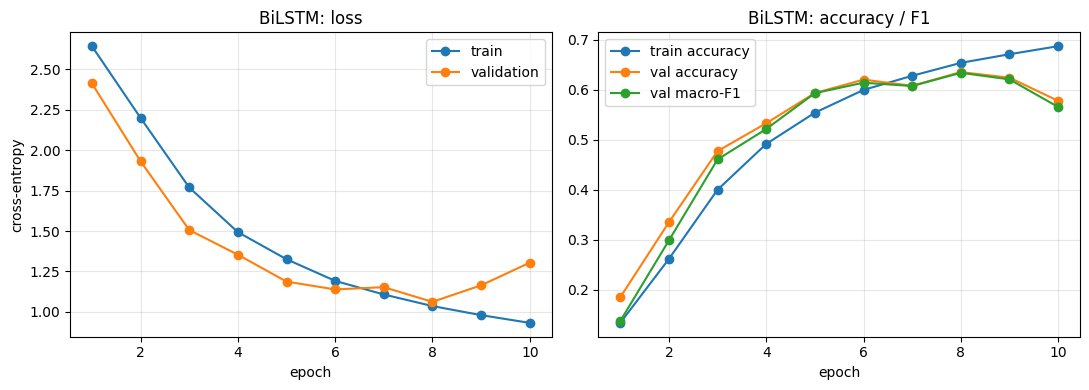


=== BiLSTM | test accuracy 0.6361 | macro-F1 0.6362 ===
              precision    recall  f1-score   support

  BLACKBOXAI      0.756     0.387     0.512       431
     ChatGPT      0.331     0.290     0.309       427
      Claude      0.940     0.726     0.819       430
     Copilot      0.623     0.488     0.548       430
      DeepAI      0.899     0.438     0.589       427
    DeepSeek      0.743     0.594     0.661       429
      Gemini      0.702     0.715     0.708       431
       Gemma      0.750     0.856     0.800       431
        Grok      0.931     0.689     0.792       431
       Llama      0.843     0.708     0.769       431
  Mistral AI      0.592     0.610     0.601       433
        Nova      0.471     0.575     0.518       431
  Perplexity      0.434     0.608     0.506       431
          Pi      0.808     0.905     0.854       433
         Poe      0.484     0.624     0.545       431
        Qwen      0.486     0.706     0.575       428
        Z.ai      0.590 

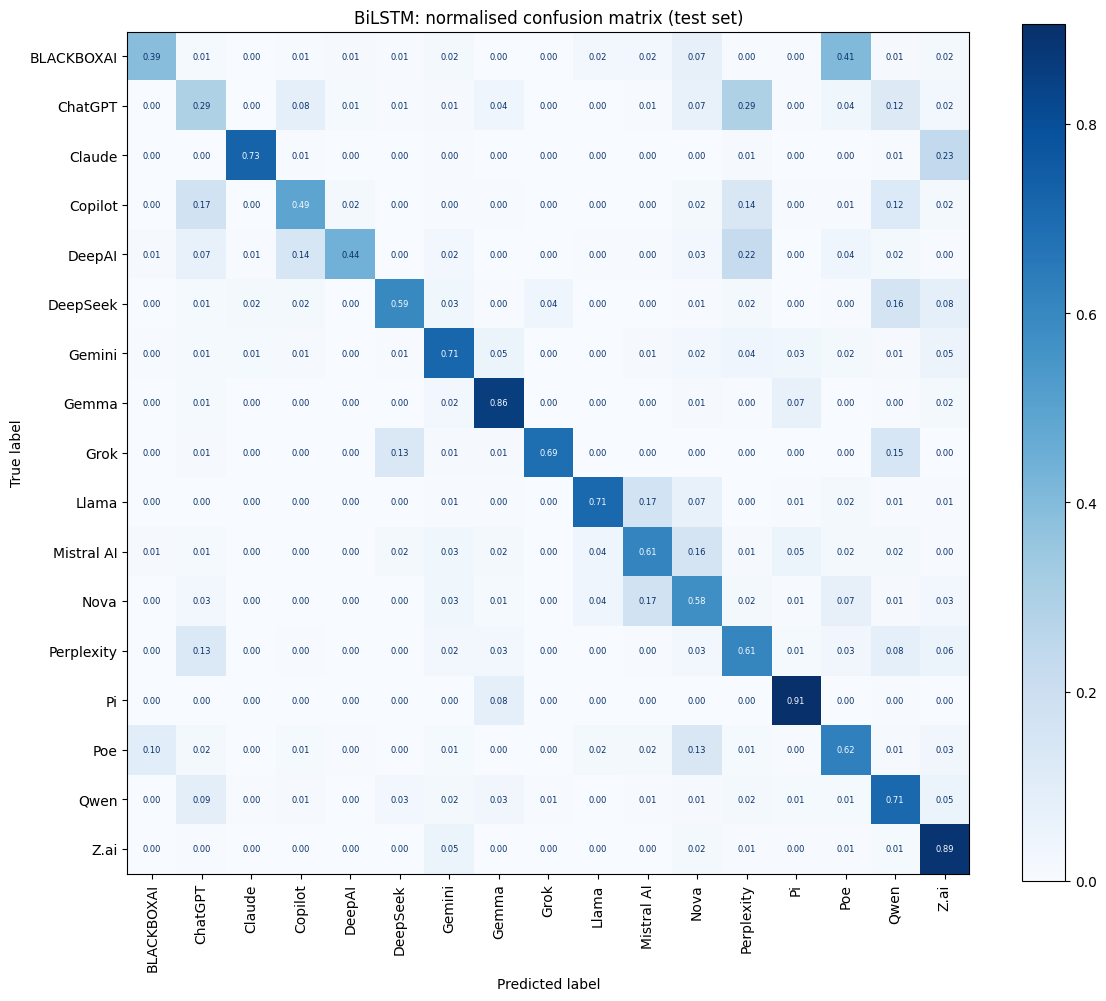

In [13]:
set_seed(CONFIG.seed)
lstm_model = train_and_evaluate(
    "BiLSTM",
    BiLSTMClassifier(
        vocab_size=len(vocab), embed_dim=CONFIG.embed_dim, num_classes=len(CLASS_NAMES),
        hidden_dim=CONFIG.lstm_hidden_dim, num_layers=CONFIG.lstm_num_layers,
        dropout=CONFIG.dropout,
    ),
)

## 12. Summary

The table below (also saved as `results/rq1_summary.csv`) is the headline
result for RQ1. Compare the neural models with the majority-class floor and
the TF-IDF baseline, and use the confusion matrices to see *which* LLMs get
confused with each other (often models from the same family or version line).

In [14]:
summary = pd.DataFrame(ALL_RESULTS).T
summary.index.name = "model"
summary[["accuracy", "macro_f1"]] = summary[["accuracy", "macro_f1"]].astype(float).round(4)
summary.to_csv(RESULTS_DIR / "rq1_summary.csv")
print(summary.to_string())

run_info = {
    "config": asdict(CONFIG),
    "classes": CLASS_NAMES,
    "split_sizes": {"train": len(train_df), "val": len(val_df), "test": len(test_df)},
    "vocab_size": len(vocab),
    "device": str(DEVICE),
    "results": ALL_RESULTS,
}
(RESULTS_DIR / "rq1_run_info.json").write_text(json.dumps(run_info, indent=2, default=str))
print(f"\nAll outputs saved to {RESULTS_DIR.resolve()}")

                 accuracy  macro_f1  train_seconds  parameters  best_epoch
model                                                                     
Majority class     0.0584    0.0065            NaN         NaN         NaN
TF-IDF + LogReg    0.7290    0.7230           92.1         NaN         NaN
TextCNN            0.6376    0.6321           81.7   4621713.0         5.0
BiLSTM             0.6361    0.6362          222.9   4686737.0         8.0

All outputs saved to /content/results
